# Model Experimentation: Lending Club Default Prediction

**Objective.** Identify as many actual defaulters (class 1) as possible while limiting false positives, i.e. good borrowers flagged as defaulters.

**Evaluation design**
- Models are fit and tuned on the training period only, using time-ordered cross-validation.
- Model and threshold selection use the full validation period (out-of-time).
- The test period is scored once, with the selected model and the frozen threshold.
- Models are compared with threshold-free metrics (ROC-AUC, PR-AUC, precision at fixed recall) and with expected cost at each model's best threshold.
- A missed defaulter (false negative) costs `COST_RATIO` times a rejected good borrower (false positive), so the expected cost per loan is `(FP + COST_RATIO * FN) / N`.
- Because catching defaulters is the main goal, the selected threshold must also reach `MIN_RECALL` on class 1; among the thresholds that do, the one with the lowest expected cost is chosen.

**Contents:** 1. Setup · 2. Data · 3. Encoding · 4. Hyperparameter tuning · 5. Model comparison · 6. Threshold selection · 7. Test evaluation · 8. Production pipeline · 9. Conclusion

## 1. Setup

In [161]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

# Cost of a missed defaulter relative to a rejected good borrower (1 : COST_RATIO)
COST_RATIO = 4

# Minimum share of defaulters (class 1 recall) the selected threshold must catch
MIN_RECALL = 0.50

# Decision thresholds scanned on the validation period
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

# Recall targets used for the precision comparison
RECALL_LEVELS = (0.3, 0.4, 0.5, 0.6)

DATA_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")

## 2. Data

Train, validation and test are consecutive issue-date periods produced in notebook 05. The test period is only loaded here; it is prepared and scored in Section 7.

In [162]:
train = pd.read_parquet(DATA_DIR / "train.parquet")
valid = pd.read_parquet(DATA_DIR / "valid.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")

# The periods must not overlap and must follow each other in time
assert train["issue_d"].max() < valid["issue_d"].min()
assert valid["issue_d"].max() < test["issue_d"].min()

frames = {"train": train, "valid": valid, "test": test}
summary = pd.DataFrame(
    {
        "rows": [len(df) for df in frames.values()],
        "first_issue_d": [df["issue_d"].min() for df in frames.values()],
        "last_issue_d": [df["issue_d"].max() for df in frames.values()],
        "default_rate": [df["default"].mean().round(4) for df in frames.values()],
        "duplicates": [df.duplicated().sum() for df in frames.values()],
        "missing_values": [df.isnull().sum().sum() for df in frames.values()],
    },
    index=list(frames),
)
display(summary)

,rows,first_issue_d,last_issue_d,default_rate,duplicates,missing_values
train,95902,2007-06-01,2012-12-01,0.1572,0,0
valid,134804,2013-01-01,2013-12-01,0.1560,0,0
test,223103,2014-01-01,2014-12-01,0.1845,0,0


## 3. Encoding

Categorical features are one-hot encoded; the encoder is fitted on the training period only. Training rows are sorted by issue date so that the time-ordered cross-validation in Section 4 respects chronology.

In [163]:
def prepare(df):
    """Drop columns that are not model inputs and cast credit history to whole years."""
    df = df.drop(columns=["issue_d", "addr_state"]).copy()
    df["credit_hist_years"] = df["credit_hist_years"].floordiv(1).astype("int64")
    return df


def split_xy(df):
    return df.drop(columns="default"), df["default"]


X_train, y_train = split_xy(prepare(train.sort_values("issue_d", kind="stable")))
X_valid, y_valid = split_xy(prepare(valid))
assert list(X_valid.columns) == list(X_train.columns)

categorical_cols = ["home_ownership", "purpose", "verification_status"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_cols,
        )
    ],
    remainder="passthrough",
)

X_train_enc = preprocessor.fit_transform(X_train)
X_valid_enc = preprocessor.transform(X_valid)

print("Train:", X_train_enc.shape, "| Valid:", X_valid_enc.shape)

Train: (95902, 86) | Valid: (134804, 86)


## 4. Hyperparameter tuning (training data only)

Both models are tuned on ROC-AUC with time-ordered folds: every fold is trained on earlier loans and scored on later ones.

In [164]:
cv = TimeSeriesSplit(n_splits=3)

xgb_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.03, 0.1],
        "min_child_weight": [1, 5],
        "subsample": [0.8],
        "colsample_bytree": [0.8],
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=True,
)
xgb_search.fit(X_train_enc, y_train)

print("XGBoost best CV ROC-AUC:", round(xgb_search.best_score_, 4))
print(xgb_search.best_params_)

XGBoost best CV ROC-AUC: 0.6929
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 100, 'subsample': 0.8}


In [165]:
lr_search = GridSearchCV(
    estimator=Pipeline(
        [
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        ]
    ),
    param_grid={
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)
lr_search.fit(X_train_enc, y_train)

print("Logistic Regression best CV ROC-AUC:", round(lr_search.best_score_, 4))
print(lr_search.best_params_)

Logistic Regression best CV ROC-AUC: 0.6763
{'model__C': 0.01, 'model__class_weight': None}


**Regularization.** XGBoost already applies L2 regularization by default (`reg_lambda=1`). The grid below starts from the tuned configuration and adds L1 (`reg_alpha`), L2 (`reg_lambda`) and split-penalty (`gamma`) values; the defaults are part of the grid, so regularization is kept only if it improves time-ordered CV. It is tuned on the training period only, with the same folds and metric as above.

In [166]:
reg_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **xgb_search.best_params_,
    ),
    param_grid={
        "reg_lambda": [1, 5, 10, 50],
        "reg_alpha": [0, 1, 5],
        "gamma": [0, 0.5, 1],
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=True,
)
reg_search.fit(X_train_enc, y_train)

print("XGBoost + regularization best CV ROC-AUC:", round(reg_search.best_score_, 4))
print(reg_search.best_params_)

XGBoost + regularization best CV ROC-AUC: 0.6933
{'gamma': 0, 'reg_alpha': 0, 'reg_lambda': 50}


In [167]:
# A large gap between train and CV ROC-AUC indicates overfitting
searches = {
    "XGBoost": xgb_search,
    "XGBoost + regularization": reg_search,
    "Logistic Regression": lr_search,
}
cv_summary = pd.DataFrame(
    {
        "Model": list(searches),
        "CV_ROC_AUC": [s.best_score_ for s in searches.values()],
        "CV_Std": [s.cv_results_["std_test_score"][s.best_index_] for s in searches.values()],
        "Train_ROC_AUC": [s.cv_results_["mean_train_score"][s.best_index_] for s in searches.values()],
    }
)
display(cv_summary.round(4))

,Model,CV_ROC_AUC,CV_Std,Train_ROC_AUC
0,XGBoost,0.6929,0.0054,0.7303
1,XGBoost + regularization,0.6933,0.0069,0.7228
2,Logistic Regression,0.6763,0.0168,0.7021


## 5. Model comparison on the validation period

Ranking quality is compared without a threshold: ROC-AUC, PR-AUC and the best precision reachable at fixed recall levels.

In [168]:
models = {name: s.best_estimator_ for name, s in searches.items()}
valid_proba = {name: m.predict_proba(X_valid_enc)[:, 1] for name, m in models.items()}

rows = []
for name, proba in valid_proba.items():
    precision, recall, _ = precision_recall_curve(y_valid, proba)
    row = {
        "Model": name,
        "ROC_AUC": roc_auc_score(y_valid, proba),
        "PR_AUC": average_precision_score(y_valid, proba),
    }
    for level in RECALL_LEVELS:
        row[f"Precision@Recall={level:.0%}"] = precision[recall >= level].max()
    rows.append(row)

ranking = pd.DataFrame(rows).set_index("Model")
display(ranking.round(4))
print(f"Validation default rate (precision of a random flag): {y_valid.mean():.4f}")

,ROC_AUC,PR_AUC,Precision@Recall=30%,Precision@Recall=40%,Precision@Recall=50%,Precision@Recall=60%
Model,,,,,,
XGBoost,0.6884,0.2834,0.3185,0.2940,0.2716,0.2517
XGBoost + regularization,0.6881,0.2817,0.3168,0.2934,0.2725,0.2517
Logistic Regression,0.6839,0.2789,0.3146,0.2906,0.2687,0.2491


Validation default rate (precision of a random flag): 0.1560


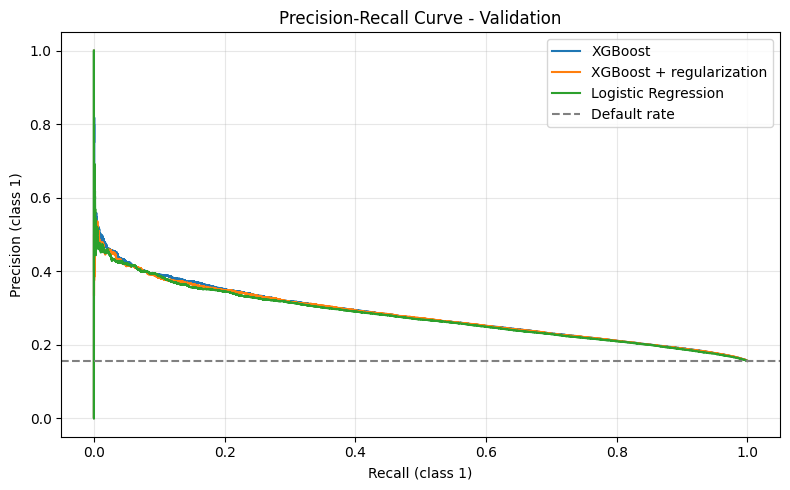

In [169]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, proba in valid_proba.items():
    precision, recall, _ = precision_recall_curve(y_valid, proba)
    ax.plot(recall, precision, label=name)
ax.axhline(y_valid.mean(), ls="--", color="grey", label="Default rate")
ax.set_xlabel("Recall (class 1)")
ax.set_ylabel("Precision (class 1)")
ax.set_title("Precision-Recall Curve - Validation")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Threshold selection on validation data

For each model, every threshold is scored with the expected cost per loan, `(FP + COST_RATIO * FN) / N`. Only thresholds that reach `MIN_RECALL` on class 1 are eligible; the model and threshold with the lowest cost among them are selected and frozen for the test period.

In [170]:
def threshold_table(y_true, proba, thresholds=THRESHOLDS, cost_ratio=COST_RATIO):
    """Confusion counts, class-1 metrics and expected cost per loan at each threshold."""
    y = np.asarray(y_true)
    thresholds = np.asarray(thresholds)
    flagged = proba[None, :] >= thresholds[:, None]

    tp = (flagged & (y == 1)).sum(axis=1)
    fp = (flagged & (y == 0)).sum(axis=1)
    fn = (y == 1).sum() - tp
    tn = (y == 0).sum() - fp

    precision = tp / np.maximum(tp + fp, 1)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

    return pd.DataFrame(
        {
            "Threshold": thresholds,
            "Accuracy": (tp + tn) / len(y),
            "Precision_1": precision,
            "Recall_1": recall,
            "Recall_0": tn / (tn + fp),
            "F1_1": f1,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Cost": (cost_ratio * fn + fp) / len(y),
        }
    )


tables = {name: threshold_table(y_valid, proba) for name, proba in valid_proba.items()}

# Reference cost: approve every loan, so every defaulter is missed
approve_all_cost = COST_RATIO * y_valid.mean()

def best_threshold_row(t, min_recall=MIN_RECALL):
    """Lowest-cost row among the thresholds that reach the recall floor."""
    eligible = t[t["Recall_1"] >= min_recall]
    return eligible.loc[eligible["Cost"].idxmin()]


best_rows = pd.DataFrame({name: best_threshold_row(t) for name, t in tables.items()}).T
best_rows.index.name = "Model"

display(best_rows.round(4))
print(f"Expected cost per loan if every loan is approved: {approve_all_cost:.4f}")

,Threshold,Accuracy,Precision_1,Recall_1,Recall_0,F1_1,TN,FP,FN,TP,Cost
Model,,,,,,,,,,,
XGBoost,0.19,0.6976,0.2653,0.5304,0.7285,0.3537,82894.0,30886.0,9873.0,11151.0,0.5221
XGBoost + regularization,0.19,0.6990,0.2662,0.5297,0.7302,0.3544,83087.0,30693.0,9888.0,11136.0,0.5211
Logistic Regression,0.19,0.6931,0.2628,0.5364,0.7220,0.3528,82150.0,31630.0,9746.0,11278.0,0.5238


Expected cost per loan if every loan is approved: 0.6238


In [171]:
selected_name = best_rows["Cost"].astype(float).idxmin()
selected_model = models[selected_name]
chosen_threshold = float(best_rows.loc[selected_name, "Threshold"])

selected_table = tables[selected_name]
valid_row = selected_table.loc[selected_table["Threshold"] == chosen_threshold].iloc[0]

# Reference: the unconstrained cost minimum for the selected model
cost_optimum = selected_table.loc[selected_table["Cost"].idxmin()]

print(f"Selected model: {selected_name}")
print(f"Selected threshold: {chosen_threshold:.2f} (recall floor {MIN_RECALL:.0%})")
print(
    f"Without the recall floor: threshold {cost_optimum['Threshold']:.2f}, "
    f"recall {cost_optimum['Recall_1']:.1%}, cost {cost_optimum['Cost']:.4f}"
)

Selected model: XGBoost + regularization
Selected threshold: 0.19 (recall floor 50%)
Without the recall floor: threshold 0.20, recall 49.1%, cost 0.5201


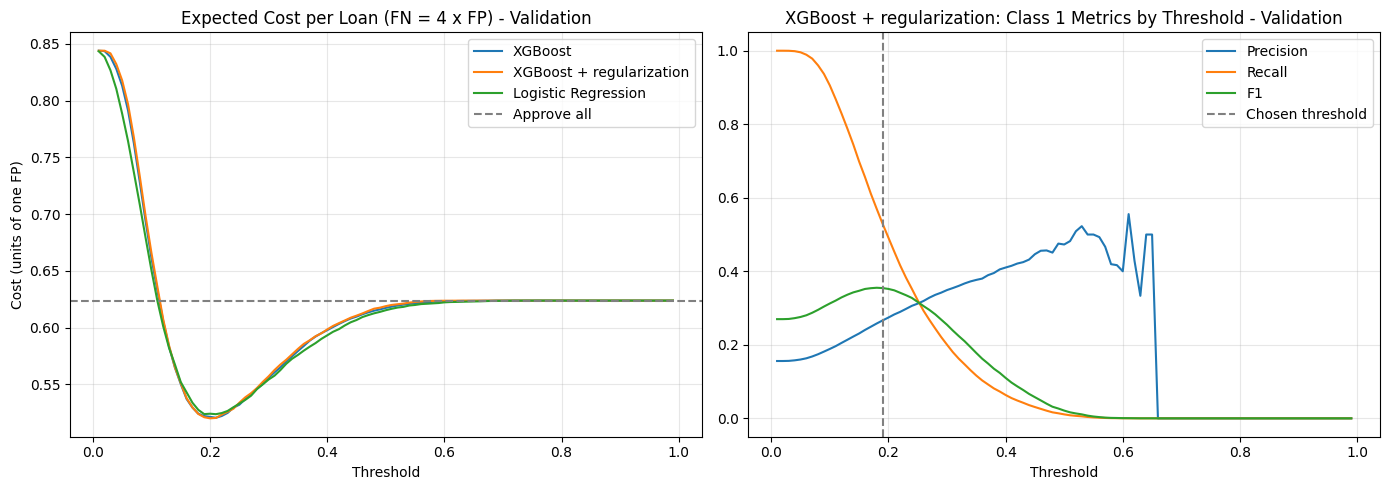

In [172]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, t in tables.items():
    axes[0].plot(t["Threshold"], t["Cost"], label=name)
axes[0].axhline(approve_all_cost, ls="--", color="grey", label="Approve all")
axes[0].set_title(f"Expected Cost per Loan (FN = {COST_RATIO} x FP) - Validation")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Cost (units of one FP)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(selected_table["Threshold"], selected_table["Precision_1"], label="Precision")
axes[1].plot(selected_table["Threshold"], selected_table["Recall_1"], label="Recall")
axes[1].plot(selected_table["Threshold"], selected_table["F1_1"], label="F1")
axes[1].axvline(chosen_threshold, ls="--", color="grey", label="Chosen threshold")
axes[1].set_title(f"{selected_name}: Class 1 Metrics by Threshold - Validation")
axes[1].set_xlabel("Threshold")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Local view.** Metrics and cost on thresholds adjacent to the chosen one, scored on the validation period.

In [173]:
nearby = np.round(chosen_threshold + np.arange(-0.06, 0.07, 0.02), 2)
nearby = nearby[(nearby > 0) & (nearby < 1)]

display(
    threshold_table(y_valid, valid_proba[selected_name], thresholds=nearby)
    [["Threshold", "Precision_1", "Recall_1", "F1_1", "FP", "FN", "Cost"]]
    .round(4)
)

,Threshold,Precision_1,Recall_1,F1_1,FP,FN,Cost
0,0.13,0.2138,0.7881,0.3363,60938,4456,0.5843
1,0.15,0.2308,0.6986,0.3470,48942,6337,0.5511
2,0.17,0.2492,0.6112,0.3540,38714,8175,0.5298
3,0.19,0.2662,0.5297,0.3544,30693,9888,0.5211
4,0.21,0.2826,0.4534,0.3482,24198,11491,0.5205
5,0.23,0.2977,0.3828,0.3349,18981,12977,0.5259
6,0.25,0.3121,0.3212,0.3166,14887,14271,0.5339


**Cost-ratio sensitivity.** How the cost-minimizing threshold moves if the assumed FN-to-FP cost ratio changes.

In [174]:
sensitivity = []
for ratio in sorted({1, 2, 3, 5, 8, COST_RATIO}):
    t = threshold_table(y_valid, valid_proba[selected_name], cost_ratio=ratio)
    best = t.loc[t["Cost"].idxmin()]
    sensitivity.append(
        {
            "Cost_ratio_FN_to_FP": ratio,
            "Threshold": best["Threshold"],
            "Precision_1": best["Precision_1"],
            "Recall_1": best["Recall_1"],
            "F1_1": best["F1_1"],
            "FP": int(best["FP"]),
            "FN": int(best["FN"]),
        }
    )

display(pd.DataFrame(sensitivity).round(4))

,Cost_ratio_FN_to_FP,Threshold,Precision_1,Recall_1,F1_1,FP,FN
0,1,0.53,0.5227,0.0055,0.0108,105,20909
1,2,0.34,0.3724,0.1311,0.1939,4644,18268
2,3,0.24,0.3060,0.3524,0.3276,16802,13615
3,4,0.20,0.2742,0.4915,0.3520,27348,10691
4,5,0.17,0.2492,0.6112,0.3540,38714,8175
5,8,0.12,0.2052,0.8292,0.3290,67520,3591


## 7. Final evaluation on the test set

The test period is prepared, encoded with the train-fitted encoder and scored once with the selected model at the frozen threshold. Validation results at the same threshold are shown alongside for comparison.

In [175]:
X_test, y_test = split_xy(prepare(test))
assert list(X_test.columns) == list(X_train.columns)
X_test_enc = preprocessor.transform(X_test)

test_proba = selected_model.predict_proba(X_test_enc)[:, 1]
test_row = threshold_table(y_test, test_proba, thresholds=[chosen_threshold]).iloc[0]


def period_report(y_true, proba, row):
    return {
        "Default_rate": y_true.mean(),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "Precision_1": row["Precision_1"],
        "Recall_1": row["Recall_1"],
        "Recall_0": row["Recall_0"],
        "F1_1": row["F1_1"],
        "Cost": row["Cost"],
        "Cost_approve_all": COST_RATIO * y_true.mean(),
    }


final_report = pd.DataFrame(
    {
        "Validation": period_report(y_valid, valid_proba[selected_name], valid_row),
        "Test": period_report(y_test, test_proba, test_row),
    }
).T

test_roc_auc = final_report.loc["Test", "ROC_AUC"]
test_pr_auc = final_report.loc["Test", "PR_AUC"]
test_approve_all_cost = final_report.loc["Test", "Cost_approve_all"]

print(f"Model: {selected_name} | frozen threshold: {chosen_threshold:.2f}")
display(final_report.round(4))

Model: XGBoost + regularization | frozen threshold: 0.19


,Default_rate,ROC_AUC,PR_AUC,Precision_1,Recall_1,Recall_0,F1_1,Cost,Cost_approve_all
Validation,0.1560,0.6881,0.2817,0.2662,0.5297,0.7302,0.3544,0.5211,0.6238
Test,0.1845,0.6983,0.3358,0.3020,0.5888,0.6921,0.3992,0.5545,0.7380


In [176]:
confusion = pd.DataFrame(
    [[int(test_row["TN"]), int(test_row["FP"])], [int(test_row["FN"]), int(test_row["TP"])]],
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
)
display(confusion)

,Predicted 0,Predicted 1
Actual 0,125920,56021
Actual 1,16924,24238


Accuracy is reported only for reference: approving every loan scores higher on accuracy, so model quality is judged by class 1 recall and precision and by expected cost.

In [177]:
accuracy_model = (test_row["TN"] + test_row["TP"]) / len(y_test)
accuracy_approve_all = 1 - y_test.mean()
print(f"Accuracy at the frozen threshold: {accuracy_model:.4f}")
print(f"Accuracy of approving every loan: {accuracy_approve_all:.4f}")

Accuracy at the frozen threshold: 0.6730
Accuracy of approving every loan: 0.8155


## 8. Production pipeline

The selected model is wrapped with its preprocessing in a single scikit-learn pipeline that takes the raw feature table: one-hot encoding of the categorical columns, whole-year credit history, and removal of `issue_d` and `addr_state`. It is fitted on the training period, the same data the threshold was selected for, and saved together with the frozen threshold as `models/model.pkl`. A reload check on the validation period confirms that the saved file reproduces the selected model.

In [178]:
train_sorted = train.sort_values("issue_d", kind="stable")
input_columns = [c for c in train.columns if c != "default"]
X_train_raw = train_sorted[input_columns]
assert (train_sorted["default"].to_numpy() == y_train.to_numpy()).all()

production_preprocessor = ColumnTransformer(
    transformers=[
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_cols,
        ),
        (
            "credit_history",
            FunctionTransformer(np.floor, feature_names_out="one-to-one"),
            ["credit_hist_years"],
        ),
        ("drop_unused", "drop", ["issue_d", "addr_state"]),
    ],
    remainder="passthrough",
)

estimator = clone(selected_model)
estimator_steps = estimator.steps if isinstance(estimator, Pipeline) else [("model", estimator)]

production_pipeline = Pipeline([("preprocessor", production_preprocessor), *estimator_steps])
production_pipeline.fit(X_train_raw, y_train)

artifact = {
    "pipeline": production_pipeline,
    "threshold": chosen_threshold,
    "model_name": selected_name,
    "input_columns": input_columns,
    "cost_ratio": COST_RATIO,
    "train_period": (str(train["issue_d"].min()), str(train["issue_d"].max())),
    "versions": {
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "pandas": pd.__version__,
    },
}

MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(artifact, MODELS_DIR / "model.pkl")
print(f"Saved {MODELS_DIR / 'model.pkl'} | model: {selected_name} | threshold: {chosen_threshold:.2f}")


Saved ..\models\model.pkl | model: XGBoost + regularization | threshold: 0.19


In [179]:
loaded = joblib.load(MODELS_DIR / "model.pkl")

X_valid_raw = valid[loaded["input_columns"]]
loaded_proba = loaded["pipeline"].predict_proba(X_valid_raw)[:, 1]
loaded_row = threshold_table(y_valid, loaded_proba, thresholds=[loaded["threshold"]]).iloc[0]

reload_check = pd.DataFrame({"Selected model": valid_row, "model.pkl": loaded_row}).loc[
    ["Precision_1", "Recall_1", "FP", "FN", "Cost"]
]
display(reload_check.astype(float).round(4))

decisions = pd.DataFrame(
    {
        "default_probability": loaded_proba[:5].round(4),
        "flag_as_default": loaded_proba[:5] >= loaded["threshold"],
    }
)
display(decisions)


,Selected model,model.pkl
Precision_1,0.2662,0.2652
Recall_1,0.5297,0.5342
FP,30693.0000,31125.0000
FN,9888.0000,9792.0000
Cost,0.5211,0.5214


,default_probability,flag_as_default
0,0.0709,False
1,0.1017,False
2,0.0686,False
3,0.0672,False
4,0.1157,False


## 9. Conclusion

In [181]:
cv_std = xgb_search.cv_results_["std_test_score"][xgb_search.best_index_]
reg_gain = reg_search.best_score_ - xgb_search.best_score_
if reg_gain > cv_std:
    reg_verdict = "an improvement larger than the fold-to-fold spread"
else:
    reg_verdict = "no gain beyond the fold-to-fold spread"

roc_text = "; ".join(f"{n} {v:.4f}" for n, v in ranking["ROC_AUC"].items())
pr_text = "; ".join(f"{n} {v:.4f}" for n, v in ranking["PR_AUC"].items())
lift = test_row["Precision_1"] / y_test.mean()

display(Markdown(f"""
**What I set out to do.** Predict which Lending Club loans will default, catching as many defaulters as possible without rejecting too many good borrowers. I treated a missed defaulter as {COST_RATIO}x as costly as a rejected good borrower and required the threshold to catch at least {MIN_RECALL:.0%} of defaulters.

**How I validated.** The data is split by issue date: training {pd.Timestamp(train["issue_d"].min()).year}-{pd.Timestamp(train["issue_d"].max()).year}, validation {pd.Timestamp(valid["issue_d"].min()).year}, test {pd.Timestamp(test["issue_d"].min()).year}. I tuned on the training period with time-ordered cross-validation, chose the model and threshold on validation, and scored test once with the frozen choice.

**Models.** I compared XGBoost, XGBoost with extra regularization and Logistic Regression. Validation ROC-AUC: {roc_text}. Validation PR-AUC: {pr_text}. The models rank borrowers almost equally well, so the choice between them rests on small margins.

**Regularization.** I first tried L1, L2 and gamma by hand and saw no improvement; a 0.1 L2 run caught 67 more defaulters than the default but flagged 356 more good borrowers, which at a {COST_RATIO}:1 cost ratio is slightly worse. Those hand checks looked at test results, so I did not use them to select the model. In time-ordered cross-validation, regularization changed ROC-AUC by {reg_gain:+.4f} (fold std {cv_std:.4f}): {reg_verdict}. Depth-3 trees with 100 estimators are already constrained, so the limit is the information in the features, not overfitting.

**Selected model.** {selected_name} at threshold {chosen_threshold:.2f}.
Validation: recall {valid_row["Recall_1"]:.1%}, precision {valid_row["Precision_1"]:.1%}, {int(valid_row["FP"]):,} false positives, {int(valid_row["FN"]):,} false negatives.
Test: ROC-AUC {test_roc_auc:.4f}, PR-AUC {test_pr_auc:.4f}, recall {test_row["Recall_1"]:.1%}, precision {test_row["Precision_1"]:.1%}, {int(test_row["FP"]):,} false positives, {int(test_row["FN"]):,} false negatives.
Expected cost per loan was {test_row["Cost"]:.4f} against {test_approve_all_cost:.4f} for approving every loan.

**What this means.** A flagged loan is about {lift:.1f}x as likely to default as a random loan (precision {test_row["Precision_1"]:.0%} against a {y_test.mean():.1%} default rate). It is a useful screen, not a precise one: most flagged loans are good borrowers. Accuracy ({accuracy_model:.1%}) is below approving everything ({accuracy_approve_all:.1%}), so I judge the model on recall, precision and cost, not accuracy.

**Limitations.**
- ROC-AUC is about {test_roc_auc:.2f}, so separation is moderate.
- The default rate rose from {y_valid.mean():.1%} in validation to {y_test.mean():.1%} in test. Recall was {valid_row["Recall_1"]:.0%} on validation and {test_row["Recall_1"]:.0%} on test, so the recall floor is not guaranteed under drift.
- The cost ratio of {COST_RATIO} is an assumption; the sensitivity table shows how the threshold moves if it changes.

**Saved model.** `models/model.pkl` holds the full pipeline (encoding and model), the frozen threshold and the library versions. Raw feature rows go in; a probability at or above the threshold is flagged as a likely default.
"""))



**What I set out to do.** Predict which Lending Club loans will default, catching as many defaulters as possible without rejecting too many good borrowers. I treated a missed defaulter as 4x as costly as a rejected good borrower and required the threshold to catch at least 50% of defaulters.

**How I validated.** The data is split by issue date: training 2007-2012, validation 2013, test 2014. I tuned on the training period with time-ordered cross-validation, chose the model and threshold on validation, and scored test once with the frozen choice.

**Models.** I compared XGBoost, XGBoost with extra regularization and Logistic Regression. Validation ROC-AUC: XGBoost 0.6884; XGBoost + regularization 0.6881; Logistic Regression 0.6839. Validation PR-AUC: XGBoost 0.2834; XGBoost + regularization 0.2817; Logistic Regression 0.2789. The models rank borrowers almost equally well, so the choice between them rests on small margins.

**Regularization.** I first tried L1, L2 and gamma by hand and saw no improvement; a 0.1 L2 run caught 67 more defaulters than the default but flagged 356 more good borrowers, which at a 4:1 cost ratio is slightly worse. Those hand checks looked at test results, so I did not use them to select the model. In time-ordered cross-validation, regularization changed ROC-AUC by +0.0004 (fold std 0.0054): no gain beyond the fold-to-fold spread. Depth-3 trees with 100 estimators are already constrained, so the limit is the information in the features, not overfitting.

**Selected model.** XGBoost + regularization at threshold 0.19.
Validation: recall 53.0%, precision 26.6%, 30,693 false positives, 9,888 false negatives.
Test: ROC-AUC 0.6983, PR-AUC 0.3358, recall 58.9%, precision 30.2%, 56,021 false positives, 16,924 false negatives.
Expected cost per loan was 0.5545 against 0.7380 for approving every loan.

**What this means.** A flagged loan is about 1.6x as likely to default as a random loan (precision 30% against a 18.4% default rate). It is a useful screen, not a precise one: most flagged loans are good borrowers. Accuracy (67.3%) is below approving everything (81.6%), so I judge the model on recall, precision and cost, not accuracy.

**Limitations.**
- ROC-AUC is about 0.70, so separation is moderate.
- The default rate rose from 15.6% in validation to 18.4% in test. Recall was 53% on validation and 59% on test, so the recall floor is not guaranteed under drift.
- The cost ratio of 4 is an assumption; the sensitivity table shows how the threshold moves if it changes.

**Saved model.** `models/model.pkl` holds the full pipeline (encoding and model), the frozen threshold and the library versions. Raw feature rows go in; a probability at or above the threshold is flagged as a likely default.
